# Chapitre 8 - Cours 1 : bootstrap, maximum de vraisemblance et approche bayésienne

Ce premier notebook couvre les sections 8.1 à 8.4 du livre. Jusqu'ici, la plupart des
modèles ont été ajustés en minimisant une somme de carrés (régression) ou une
entropie croisée (classification). Ces deux minimisations sont en fait des cas
particuliers d'un principe général : le **maximum de vraisemblance**.

Nous allons :

1. reprendre l'exemple de lissage par B-splines du livre (figures 8.1 et 8.2) ;
2. mesurer l'incertitude de l'ajustement de trois façons : formule des moindres carrés,
   **bootstrap non paramétrique**, **bootstrap paramétrique** ;
3. rappeler la théorie du **maximum de vraisemblance** (score, information de Fisher,
   normalité asymptotique, intervalles fondés sur la vraisemblance) ;
4. présenter l'**approche bayésienne** sur le même exemple (figures 8.3 et 8.4) ;
5. expliquer pourquoi le bootstrap est une sorte de « loi a posteriori du pauvre »
   (section 8.4).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch08_inference as inf
set_style()
rng = np.random.RandomState(0)

## 1. L'exemple de lissage (section 8.2.1)

On dispose de $N = 50$ couples $z_i = (x_i, y_i)$ avec $x_i \in [0, 3]$ et $y_i$ réel.
Les 50 points exacts du livre ne sont pas publiés ; nous **simulons** donc un jeu de
données de même allure :

$$x_i \sim \mathcal U[0,3], \qquad y_i = \mu(x_i) + \varepsilon_i, \qquad
\mu(x) = 1 + 1{,}6\,\sin(2{,}6\,x + 0{,}9), \qquad \varepsilon_i \sim N(0, 0{,}9^2).$$

La fonction $\mu$ est bien sûr inconnue du statisticien : elle ne sert qu'à fabriquer les
données et, plus loin, à juger les méthodes.

In [2]:
N = 50
x = np.sort(rng.uniform(0, 3, N))
mu_true = lambda t: 1 + 1.6 * np.sin(2.6 * t + 0.9)
y = mu_true(x) + 0.9 * rng.randn(N)
x_grid = np.linspace(0, 3, 300)

### Base de B-splines cubiques

On choisit d'ajuster une **spline cubique** (polynôme de degré 3 par morceaux, de classe
$C^2$) avec trois nœuds intérieurs placés aux quartiles des $x_i$. L'ensemble de ces
fonctions est un espace vectoriel de dimension $3 + 4 = 7$ (nombre de nœuds intérieurs
+ degré + 1, voir chapitre 5). On en choisit une base commode, les **B-splines**
$h_1, \dots, h_7$ (section 5.9.2 du livre) :

$$\mu(x) = \sum_{j=1}^{7} \beta_j\, h_j(x). \qquad \text{(éq. (8.1) du livre)}$$

Chaque $h_j$ est positive, nulle en dehors de quatre intervalles consécutifs, et les
$h_j$ somment à 1 en tout point (« partition de l'unité »).

In [3]:
interior = np.quantile(x, [0.25, 0.5, 0.75])
knots = inf.bspline_knots(interior, (0, 3))
H = inf.bspline_basis(x, knots)            # matrice N x 7 : H[i, j] = h_j(x_i)
H_grid = inf.bspline_basis(x_grid, knots)
print("Dimensions de H :", H.shape)
print("Somme des h_j sur la grille : min = %.6f, max = %.6f"
      % (H_grid.sum(1).min(), H_grid.sum(1).max()))

Dimensions de H : (50, 7)
Somme des h_j sur la grille : min = 1.000000, max = 1.000000


**Figure 8.1.** À gauche, les données ; à droite, les sept fonctions de base, avec les
trois nœuds en pointillés.

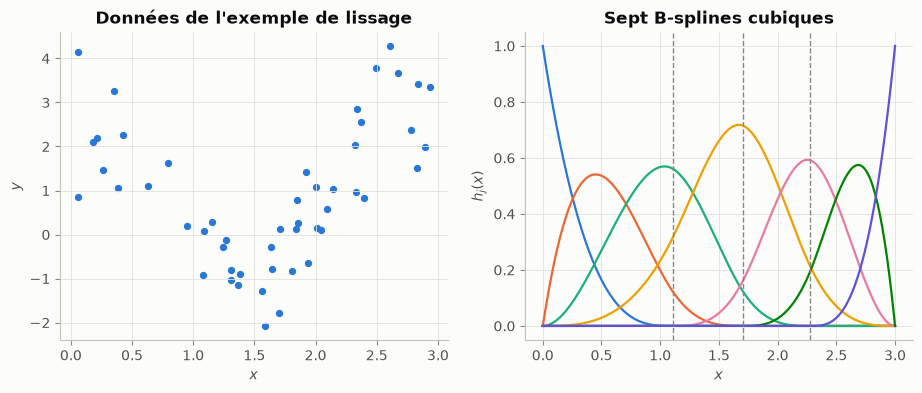

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(x, y, color=BLUE, s=18)
ax[0].set(title="Données de l'exemple de lissage", xlabel="$x$", ylabel="$y$")
for j in range(H_grid.shape[1]):
    ax[1].plot(x_grid, H_grid[:, j], color=COLORS[j % len(COLORS)], lw=1.6)
for k in interior:
    ax[1].axvline(k, color=GRAY, ls="--", lw=1)
ax[1].set(title="Sept B-splines cubiques", xlabel="$x$", ylabel="$h_j(x)$")
plt.show()

## 2. Ajustement par moindres carrés et erreurs standard

Notons $H$ la matrice $N \times 7$ d'élément $H_{ij} = h_j(x_i)$. L'estimateur des
moindres carrés minimise $\|y - H\beta\|^2$ ; en annulant le gradient $-2H^T(y - H\beta)$
on obtient les équations normales $H^TH\beta = H^Ty$, d'où (car $H^TH$ est inversible,
les colonnes de $H$ étant linéairement indépendantes) :

$$\hat\beta = (H^TH)^{-1}H^Ty. \qquad \text{(éq. (8.2))}$$

La courbe ajustée est $\hat\mu(x) = \sum_j \hat\beta_j h_j(x) = h(x)^T\hat\beta$ où
$h(x)^T = (h_1(x), \dots, h_7(x))$.

In [5]:
beta_hat, sigma2_hat, cov_beta = inf.ls_fit(H, y)
mu_hat = H_grid @ beta_hat
print("beta_hat =", np.round(beta_hat, 3))
print("sigma2_hat = %.3f   (vraie variance du bruit : %.3f)" % (sigma2_hat, 0.9 ** 2))

beta_hat = [ 2.229  2.743 -0.141 -1.447  2.264  4.096  1.781]
sigma2_hat = 0.617   (vraie variance du bruit : 0.810)


### Variance de $\hat\beta$ et de $\hat\mu(x)$

Les $x_i$ étant considérés comme fixés, $y$ a pour matrice de covariance $\sigma^2 I_N$.
Comme $\hat\beta = Ay$ avec $A = (H^TH)^{-1}H^T$, on a
$\mathrm{Var}(\hat\beta) = A(\sigma^2 I)A^T = \sigma^2 (H^TH)^{-1}H^TH(H^TH)^{-1}
= \sigma^2(H^TH)^{-1}$. En remplaçant $\sigma^2$ par
$\hat\sigma^2 = \frac1N\sum_i (y_i - \hat\mu(x_i))^2$ :

$$\widehat{\mathrm{Var}}(\hat\beta) = (H^TH)^{-1}\hat\sigma^2. \qquad \text{(éq. (8.3))}$$

Puis, $\hat\mu(x) = h(x)^T\hat\beta$ étant une combinaison linéaire de $\hat\beta$,
$\mathrm{Var}(\hat\mu(x)) = h(x)^T \mathrm{Var}(\hat\beta) h(x)$, d'où l'erreur standard

$$\widehat{\mathrm{se}}[\hat\mu(x)] = \big[h(x)^T(H^TH)^{-1}h(x)\big]^{1/2}\,\hat\sigma.
\qquad \text{(éq. (8.4))}$$

Comme 1,96 est le quantile à 97,5 % de la loi $N(0,1)$, la bande
$\hat\mu(x) \pm 1{,}96\,\widehat{\mathrm{se}}[\hat\mu(x)]$ est une bande de confiance
**ponctuelle** approximativement à 95 %.

In [6]:
se_ls = inf.pointwise_se(H_grid, cov_beta)
lo_ls, hi_ls = mu_hat - 1.96 * se_ls, mu_hat + 1.96 * se_ls

**Figure 8.2 (haut).** À gauche, la spline ajustée ; à droite, la même avec la bande
$\pm 1{,}96$ erreurs standard.

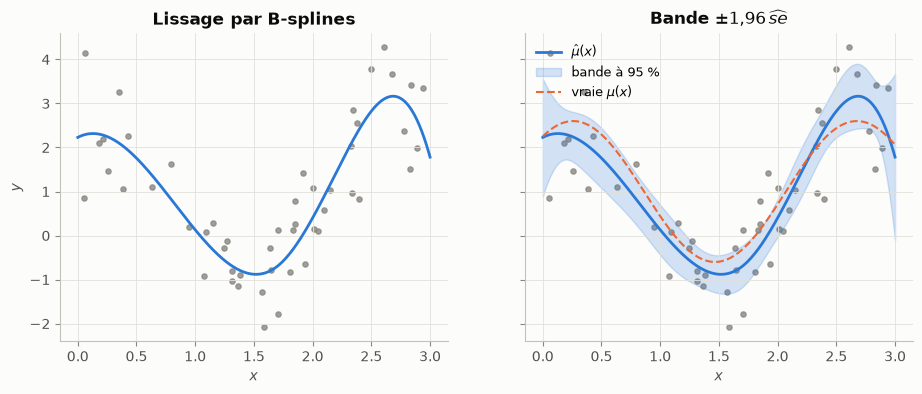

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a in ax:
    a.scatter(x, y, color=GRAY, s=14, alpha=0.8)
    a.plot(x_grid, mu_hat, color=BLUE, label=r"$\hat\mu(x)$")
    a.set(xlabel="$x$")
ax[1].fill_between(x_grid, lo_ls, hi_ls, color=BLUE, alpha=0.2, label="bande à 95 %")
ax[1].plot(x_grid, mu_true(x_grid), color=ORANGE, ls="--", lw=1.5, label=r"vraie $\mu(x)$")
ax[0].set(title="Lissage par B-splines", ylabel="$y$")
ax[1].set(title="Bande $\\pm 1{,}96\\,\\widehat{se}$")
ax[1].legend(loc="upper left")
plt.show()

## 3. Le bootstrap non paramétrique

> **Intuition.** On voudrait observer de nombreux jeux de données indépendants pour voir
> comment fluctue la courbe ajustée. On n'en a qu'un ; le bootstrap le **réutilise** en
> tirant avec remise dans l'échantillon, comme si celui-ci représentait la population.

**Algorithme.** Pour $b = 1, \dots, B$ :

1. tirer $N$ couples $z^*_1, \dots, z^*_N$ **avec remise** parmi $z_1, \dots, z_N$
   (l'unité de tirage est le couple $(x_i, y_i)$) ;
2. ajuster la spline sur cet échantillon $Z^{*b}$ : on obtient $\hat\mu^{*b}(x)$.

La dispersion des $B$ courbes $\hat\mu^{*b}$ en un point $x$ estime la variabilité de
$\hat\mu(x)$. Les nœuds restent fixés aux quartiles des données d'origine.

In [8]:
def fit_spline(xb, yb, xe):
    Hb = inf.bspline_basis(xb, knots)
    beta = np.linalg.lstsq(Hb, yb, rcond=None)[0]
    return inf.bspline_basis(xe, knots) @ beta

B = 200
boot = inf.bootstrap_curves(x, y, fit_spline, x_grid, B, rng)
print("Courbes bootstrap :", boot.shape)

Courbes bootstrap : (200, 300)


### Bande par percentiles

Avec $B = 200$, une bande ponctuelle à 95 % s'obtient en prenant, en chaque $x$, les
quantiles empiriques à 2,5 % et 97,5 % des $\hat\mu^{*b}(x)$, c'est-à-dire la
$2{,}5\% \times 200 = 5$-ième plus petite et la 5-ième plus grande valeur.

In [9]:
lo_boot, hi_boot = np.percentile(boot, [2.5, 97.5], axis=0)

**Figure 8.2 (bas).** À gauche, dix réplications bootstrap ; à droite, la bande à 95 %
issue des percentiles bootstrap, comparée à la bande des moindres carrés.

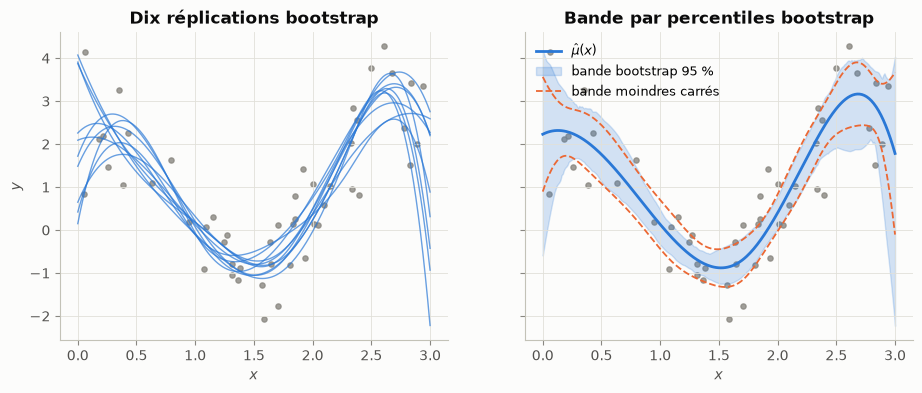

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a in ax:
    a.scatter(x, y, color=GRAY, s=14, alpha=0.8)
    a.set(xlabel="$x$")
for b in range(10):
    ax[0].plot(x_grid, boot[b], color=BLUE, lw=1, alpha=0.7)
ax[0].set(title="Dix réplications bootstrap", ylabel="$y$")
ax[1].plot(x_grid, mu_hat, color=BLUE, label=r"$\hat\mu(x)$")
ax[1].fill_between(x_grid, lo_boot, hi_boot, color=BLUE, alpha=0.2,
                   label="bande bootstrap 95 %")
ax[1].plot(x_grid, lo_ls, color=ORANGE, ls="--", lw=1.3, label="bande moindres carrés")
ax[1].plot(x_grid, hi_ls, color=ORANGE, ls="--", lw=1.3)
ax[1].set(title="Bande par percentiles bootstrap")
ax[1].legend(loc="upper left")
plt.show()

Les deux bandes se ressemblent beaucoup ; la bande bootstrap est un peu plus large aux
extrémités, là où peu de points pèsent sur l'ajustement (un échantillon bootstrap peut
omettre les quelques points extrêmes).

## 4. Le bootstrap paramétrique

Supposons de plus les erreurs gaussiennes :

$$Y = \mu(X) + \varepsilon, \quad \varepsilon \sim N(0, \sigma^2), \quad
\mu(x) = \sum_{j=1}^7 \beta_j h_j(x). \qquad \text{(éq. (8.5))}$$

Le **bootstrap paramétrique** ne rééchantillonne plus les données : il simule de
nouvelles réponses à partir du modèle ajusté,

$$y_i^* = \hat\mu(x_i) + \varepsilon_i^*, \qquad \varepsilon_i^* \sim N(0, \hat\sigma^2),
\qquad i = 1, \dots, N, \qquad \text{(éq. (8.6))}$$

les $x_i$ restant inchangés. Le bootstrap non paramétrique est dit « sans modèle »
(*model-free*) ; le paramétrique, lui, s'appuie sur le modèle (8.5).

### Loi exacte du bootstrap paramétrique

La courbe réajustée vaut $\hat\mu^*(x) = h(x)^T(H^TH)^{-1}H^Ty^*$. Or
$y^* = H\hat\beta + \varepsilon^*$ et $(H^TH)^{-1}H^TH\hat\beta = \hat\beta$, donc
$\hat\mu^*(x) = \hat\mu(x) + h(x)^T(H^TH)^{-1}H^T\varepsilon^*$. C'est une fonction
affine d'un vecteur gaussien, donc gaussienne, d'espérance $\hat\mu(x)$ et de variance
$h(x)^T(H^TH)^{-1}H^T(\hat\sigma^2 I)H(H^TH)^{-1}h(x) = h(x)^T(H^TH)^{-1}h(x)\,\hat\sigma^2$ :

$$\hat\mu^*(x) \sim N\big(\hat\mu(x),\ h(x)^T(H^TH)^{-1}h(x)\,\hat\sigma^2\big).
\qquad \text{(éq. (8.7))}$$

> **À retenir.** Quand $B \to \infty$, les bandes du bootstrap paramétrique coïncident
> exactement avec les bandes des moindres carrés : même centre, même écart-type (8.4).

In [11]:
boot_par = inf.parametric_bootstrap_curves(H, y, H_grid, 4000, rng)
sd_par = boot_par.std(axis=0)
print("Écart max |sd bootstrap paramétrique - se (8.4)| = %.4f" % np.max(np.abs(sd_par - se_ls)))
print("Écart max |moyenne bootstrap - mu_hat|         = %.4f"
      % np.max(np.abs(boot_par.mean(0) - mu_hat)))

Écart max |sd bootstrap paramétrique - se (8.4)| = 0.0061
Écart max |moyenne bootstrap - mu_hat|         = 0.0375


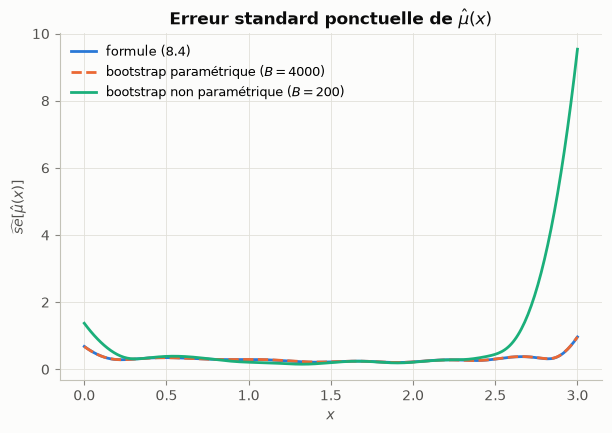

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(x_grid, se_ls, color=BLUE, label="formule (8.4)")
ax.plot(x_grid, sd_par, color=ORANGE, ls="--", label="bootstrap paramétrique ($B=4000$)")
ax.plot(x_grid, boot.std(axis=0), color=COLORS[2], label="bootstrap non paramétrique ($B=200$)")
ax.set(title="Erreur standard ponctuelle de $\\hat\\mu(x)$", xlabel="$x$",
       ylabel="$\\widehat{se}[\\hat\\mu(x)]$")
ax.legend()
plt.show()

## 5. L'inférence par maximum de vraisemblance (section 8.2.2)

Le bootstrap paramétrique coïncide avec les moindres carrés **parce que** le bruit est
gaussien. En général, il coïncide avec le **maximum de vraisemblance**, que nous
rappelons maintenant.

**Modèle paramétrique.** On suppose que les observations sont indépendantes, de densité
(ou de fonction de masse) $g_\theta(z)$ connue à un paramètre $\theta$ près :
$z_i \sim g_\theta(z)$ (éq. (8.8)). Exemple : pour la loi normale,
$\theta = (\mu, \sigma^2)$ et
$g_\theta(z) = \frac{1}{\sqrt{2\pi}\sigma} e^{-\frac12 (z-\mu)^2/\sigma^2}$
(éq. (8.9)-(8.10)).

### Vraisemblance, score, information

* **Vraisemblance** : $L(\theta; Z) = \prod_{i=1}^N g_\theta(z_i)$ (éq. (8.11)), vue
  comme une fonction de $\theta$, les données étant fixées.
* **Log-vraisemblance** : $\ell(\theta; Z) = \sum_{i=1}^N \log g_\theta(z_i)$
  (éq. (8.12)) ; le logarithme transforme le produit en somme et ne change pas le
  maximiseur (il est croissant). L'**estimateur du maximum de vraisemblance** (EMV)
  $\hat\theta$ maximise $\ell$.
* **Score** : $\dot\ell(\theta; Z) = \sum_i \partial \ell(\theta; z_i)/\partial\theta$
  (éq. (8.13)). Si le maximum est intérieur, $\dot\ell(\hat\theta; Z) = 0$.
* **Information observée** : $I(\theta) = -\sum_i \frac{\partial^2 \ell(\theta; z_i)}
  {\partial\theta\,\partial\theta^T}$ (éq. (8.14)), opposée de la hessienne : elle
  mesure la **courbure** de la log-vraisemblance. Plus elle est courbée, plus le maximum
  est « net » et plus $\hat\theta$ est précis.
* **Information de Fisher** (attendue) : $i(\theta) = E_\theta[I(\theta)]$ (éq. (8.15)).

### Normalité asymptotique

Si $\theta_0$ est la vraie valeur, un résultat classique (admis ici) affirme que, quand
$N \to \infty$,

$$\hat\theta \approx N\big(\theta_0,\ i(\theta_0)^{-1}\big). \qquad \text{(éq. (8.16))}$$

En pratique on remplace $\theta_0$ par $\hat\theta$ : $N(\hat\theta, i(\hat\theta)^{-1})$
ou $N(\hat\theta, I(\hat\theta)^{-1})$ (éq. (8.17)), d'où les erreurs standard
$\sqrt{i(\hat\theta)^{-1}_{jj}}$ ou $\sqrt{I(\hat\theta)^{-1}_{jj}}$ (éq. (8.18)) et les
bornes de confiance $\hat\theta_j \pm z^{(1-\alpha)}\sqrt{I(\hat\theta)^{-1}_{jj}}$, où
$z^{(1-\alpha)}$ est le quantile d'ordre $1-\alpha$ de $N(0,1)$.

### Illustration : loi exponentielle

Soit $z_i \sim \mathcal E(\theta)$, de densité $g_\theta(z) = \theta e^{-\theta z}$ pour
$z > 0$. Alors $\ell(\theta) = N\log\theta - \theta\sum_i z_i$, le score vaut
$\dot\ell(\theta) = N/\theta - \sum_i z_i$, qui s'annule en $\hat\theta = 1/\bar z$.
La dérivée seconde est $-N/\theta^2$, donc $I(\theta) = i(\theta) = N/\theta^2$ (elle ne
dépend pas des données). La loi limite (8.16) est donc $N(\theta_0, \theta_0^2/N)$.
Vérifions-le par simulation.

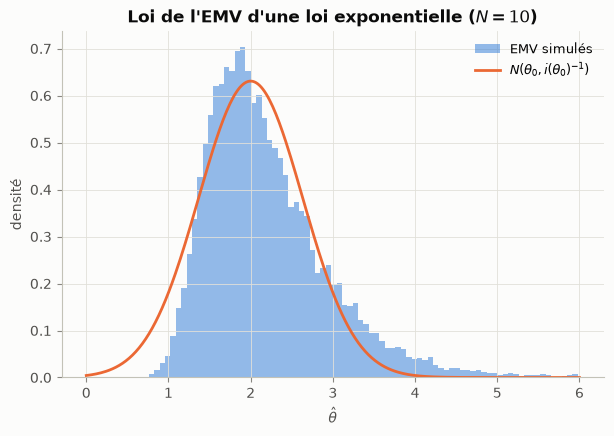

In [13]:
theta0, n_exp, R = 2.0, 10, 20000
Z = rng.exponential(1 / theta0, size=(R, n_exp))
theta_mle = 1 / Z.mean(axis=1)
tt = np.linspace(0, 6, 300)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(theta_mle[theta_mle < 6], bins=80, density=True, color=BLUE, alpha=0.5, label="EMV simulés")
ax.plot(tt, stats.norm.pdf(tt, theta0, theta0 / np.sqrt(n_exp)), color=ORANGE,
        label=r"$N(\theta_0, i(\theta_0)^{-1})$")
ax.set(title="Loi de l'EMV d'une loi exponentielle ($N=10$)", xlabel=r"$\hat\theta$",
       ylabel="densité")
ax.legend()
plt.show()

Avec seulement $N = 10$ observations, l'approximation est grossière : la loi de
$\hat\theta = 1/\bar z$ est nettement asymétrique (queue à droite).
Les intervalles fondés directement sur la vraisemblance tiennent mieux compte de
cette asymétrie.

### Intervalles fondés sur la vraisemblance

On utilise l'approximation du rapport de vraisemblance

$$2\,[\ell(\hat\theta) - \ell(\theta_0)] \approx \chi^2_p, \qquad \text{(éq. (8.19))}$$

où $p$ est la dimension de $\theta$. L'ensemble des $\theta_0$ tels que
$2[\ell(\hat\theta) - \ell(\theta_0)] \le \chi^{2\,(1-2\alpha)}_p$ est un intervalle de
confiance de niveau $1 - 2\alpha$. Comparons sa couverture à celle de l'intervalle de
Wald $\hat\theta \pm 1{,}96\,\hat\theta/\sqrt N$ sur nos 20 000 simulations
(niveau visé : 95 %, soit idéalement 2,5 % d'échecs de chaque côté).

In [14]:
def loglik_exp(theta, s, n):
    return n * np.log(theta) - theta * s

S = Z.sum(axis=1)
c95 = stats.chi2.ppf(0.95, 1)
in_lr = 2 * (loglik_exp(theta_mle, S, n_exp) - loglik_exp(theta0, S, n_exp)) <= c95
in_wald = np.abs(theta_mle - theta0) <= 1.96 * theta_mle / np.sqrt(n_exp)
# côté où l'intervalle « rate » theta0 (theta0 au-dessus ou au-dessous de l'intervalle)
above = theta0 > theta_mle
print("Rapport de vraisemblance : couverture %.3f | theta0 trop haut %.3f, trop bas %.3f"
      % (in_lr.mean(), np.mean(~in_lr & above), np.mean(~in_lr & ~above)))
print("Wald (8.18)              : couverture %.3f | theta0 trop haut %.3f, trop bas %.3f"
      % (in_wald.mean(), np.mean(~in_wald & above), np.mean(~in_wald & ~above)))

Rapport de vraisemblance : couverture 0.952 | theta0 trop haut 0.019, trop bas 0.028
Wald (8.18)              : couverture 0.957 | theta0 trop haut 0.038, trop bas 0.005


Les deux couvertures globales sont proches de 95 %, mais l'intervalle de Wald, symétrique
autour de $\hat\theta$, se trompe de façon très déséquilibrée : il « rate » $\theta_0$
presque toujours du même côté. L'intervalle du rapport de vraisemblance, asymétrique
comme la vraisemblance elle-même, répartit mieux ses erreurs.

### Retour à l'exemple de lissage

Ici $\theta = (\beta, \sigma^2)$ et, d'après la densité gaussienne,

$$\ell(\theta) = -\frac N2 \log(2\pi\sigma^2) - \frac{1}{2\sigma^2}
\sum_{i=1}^N \big(y_i - h(x_i)^T\beta\big)^2. \qquad \text{(éq. (8.20))}$$

* $\partial\ell/\partial\beta = \frac{1}{\sigma^2}H^T(y - H\beta) = 0$ donne
  $\hat\beta = (H^TH)^{-1}H^Ty$ : à $\sigma^2$ fixé, maximiser $\ell$ revient à
  minimiser la somme des carrés.
* $\partial\ell/\partial\sigma^2 = -\frac{N}{2\sigma^2} + \frac{1}{2\sigma^4}
  \sum_i (y_i - \hat\mu(x_i))^2 = 0$ donne
  $\hat\sigma^2 = \frac1N\sum_i (y_i - \hat\mu(x_i))^2$ (éq. (8.21)).
* La dérivée seconde en $\beta$ vaut $-H^TH/\sigma^2$, d'où le bloc d'information
  $I(\beta) = H^TH/\sigma^2$ (éq. (8.22)), dont l'inverse est exactement (8.3).
  Les dérivées croisées $\partial^2\ell/\partial\beta\,\partial\sigma^2 =
  -\frac{1}{\sigma^4}H^T(y - H\beta)$ s'annulent en $\hat\beta$ : l'information est
  bloc-diagonale.

In [15]:
from scipy.optimize import minimize
negll = lambda th: -(-N / 2 * np.log(2 * np.pi * np.exp(th[-1]))
                     - np.sum((y - H @ th[:-1]) ** 2) / (2 * np.exp(th[-1])))
res = minimize(negll, np.r_[np.zeros(7), 0.0], method="BFGS")
print("EMV numérique de beta :", np.round(res.x[:-1], 3))
print("Formule (8.21)        :", np.round(beta_hat, 3))
print("sigma2 : numérique %.4f, formule %.4f" % (np.exp(res.x[-1]), sigma2_hat))

EMV numérique de beta : [ 2.229  2.743 -0.141 -1.447  2.264  4.096  1.781]
Formule (8.21)        : [ 2.229  2.743 -0.141 -1.447  2.264  4.096  1.781]
sigma2 : numérique 0.6173, formule 0.6173


## 6. Bootstrap et maximum de vraisemblance (section 8.2.3)

> **À retenir.** Le bootstrap est une mise en œuvre **numérique** du maximum de
> vraisemblance (non paramétrique ou paramétrique). Son avantage : il fournit des
> erreurs standard là où aucune formule n'existe.

Exemple : choisissons le **nombre de nœuds** $\lambda$ par validation croisée
« leave-one-out » (parmi 1 à 8 nœuds placés aux quantiles). Aucune formule ne tient
compte de ce choix adaptatif ; le bootstrap si : on refait le choix de $\lambda$ sur
**chaque** échantillon bootstrap.

In [16]:
def fit_adaptive(xb, yb, xe, max_knots=8):
    best = None
    for k in range(1, max_knots + 1):
        # nœuds aux quantiles des x d'origine (positions candidates fixées)
        kn = inf.bspline_knots(np.quantile(x, np.arange(1, k + 1) / (k + 1)), (0, 3))
        Hb = inf.bspline_basis(xb, kn)
        try:   # la constante est la somme des h_j : on retire une colonne
            with np.errstate(divide="ignore", invalid="ignore"):
                fitted, loo = inf.loo_residuals_linear(Hb[:, 1:], yb)
            cv = np.mean(loo ** 2)
        except np.linalg.LinAlgError:
            continue
        if not np.isfinite(cv):
            continue
        if best is None or cv < best[0]:
            best = (cv, kn, k)
    kn = best[1]
    beta = np.linalg.lstsq(inf.bspline_basis(xb, kn), yb, rcond=None)[0]
    return inf.bspline_basis(xe, kn) @ beta, best[2]

f_ad, k_ad = fit_adaptive(x, y, x_grid)
print("Nombre de nœuds choisi sur les données :", k_ad)

Nombre de nœuds choisi sur les données : 1


In [17]:
idx = inf.bootstrap_indices(N, 200, rng)
res_ad = [fit_adaptive(x[i], y[i], x_grid) for i in idx]
boot_ad = np.array([r[0] for r in res_ad])
k_boot = np.array([r[1] for r in res_ad])
for k, c in zip(*np.unique(k_boot, return_counts=True)):
    print("%d nœud(s) choisi(s) sur %3d échantillons bootstrap" % (k, c))

1 nœud(s) choisi(s) sur  86 échantillons bootstrap
2 nœud(s) choisi(s) sur  16 échantillons bootstrap
3 nœud(s) choisi(s) sur   8 échantillons bootstrap
4 nœud(s) choisi(s) sur  19 échantillons bootstrap
5 nœud(s) choisi(s) sur   5 échantillons bootstrap
6 nœud(s) choisi(s) sur  14 échantillons bootstrap
7 nœud(s) choisi(s) sur  26 échantillons bootstrap
8 nœud(s) choisi(s) sur  26 échantillons bootstrap


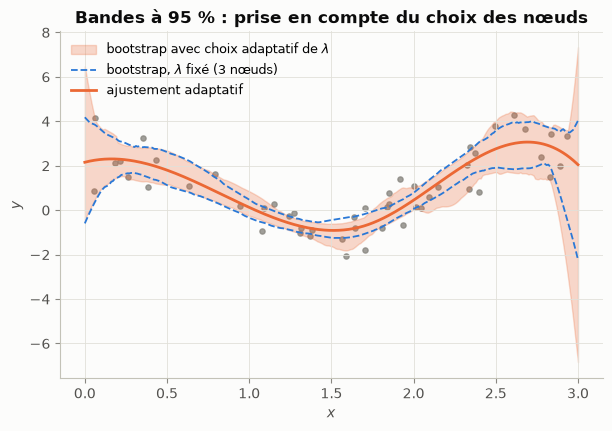

In [18]:
lo_ad, hi_ad = np.percentile(boot_ad, [2.5, 97.5], axis=0)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(x, y, color=GRAY, s=14, alpha=0.8)
ax.fill_between(x_grid, lo_ad, hi_ad, color=ORANGE, alpha=0.25,
                label=r"bootstrap avec choix adaptatif de $\lambda$")
ax.plot(x_grid, lo_boot, color=BLUE, ls="--", lw=1.3, label=r"bootstrap, $\lambda$ fixé (3 nœuds)")
ax.plot(x_grid, hi_boot, color=BLUE, ls="--", lw=1.3)
ax.plot(x_grid, f_ad, color=ORANGE, label="ajustement adaptatif")
ax.set(title="Bandes à 95 % : prise en compte du choix des nœuds", xlabel="$x$", ylabel="$y$")
ax.legend(loc="upper left")
plt.show()

Au centre, les deux bandes sont proches (c'est ce qu'observe le livre sur ses données).
Aux extrémités, en revanche, la bande adaptative est nettement plus large : sur certains
échantillons bootstrap la validation croisée retient beaucoup de nœuds et la courbe
devient instable près des bords. Cette variabilité supplémentaire, due au choix de
$\hat\lambda$, est invisible dans les formules à $\lambda$ fixé.

> **Remarque.** Un échantillon bootstrap contient des points répétés ; la validation
> croisée « leave-one-out » y laisse une copie du point retiré dans l'échantillon, ce qui
> la pousse vers des modèles plus complexes. C'est une limite connue de la combinaison
> bootstrap + validation croisée.

## 7. L'approche bayésienne (section 8.3)

En statistique bayésienne, le paramètre $\theta$ est lui-même traité comme **aléatoire**.
On se donne :

* un **modèle d'échantillonnage** $\Pr(Z \mid \theta)$ (densité des données sachant le
  paramètre) ;
* une **loi a priori** $\Pr(\theta)$ qui résume ce que l'on sait de $\theta$ avant
  d'observer les données.

La formule de Bayes donne alors la **loi a posteriori**

$$\Pr(\theta \mid Z) = \frac{\Pr(Z\mid\theta)\Pr(\theta)}{\int \Pr(Z\mid\theta)
\Pr(\theta)\,d\theta}, \qquad \text{(éq. (8.23))}$$

connaissance actualisée sur $\theta$ après observation. Pour prédire une nouvelle
observation, on utilise la **loi prédictive**

$$\Pr(z^{\text{new}}\mid Z) = \int \Pr(z^{\text{new}}\mid\theta)\Pr(\theta\mid Z)\,d\theta,
\qquad \text{(éq. (8.24))}$$

qui, contrairement à $\Pr(z^{\text{new}}\mid\hat\theta)$, tient compte de l'incertitude
sur $\theta$.

### A priori gaussien sur les coefficients

Reprenons le modèle (8.5), avec $\sigma^2$ supposé connu et les $x_i$ fixés. Plutôt
qu'une loi sur les fonctions, on met une loi sur $\beta$ :

$$\beta \sim N(0, \tau\Sigma). \qquad \text{(éq. (8.25))}$$

Elle induit une loi a priori gaussienne sur la fonction $\mu(x) = h(x)^T\beta$, de
covariance

$$K(x, x') = \mathrm{cov}[\mu(x), \mu(x')] = \tau\, h(x)^T\Sigma\, h(x'). \qquad
\text{(éq. (8.26))}$$

Comme la base de B-splines garantit déjà la régularité, on prend $\Sigma = I$.
**Figure 8.3** : dix tirages de cette loi a priori ($\tau = 1$).

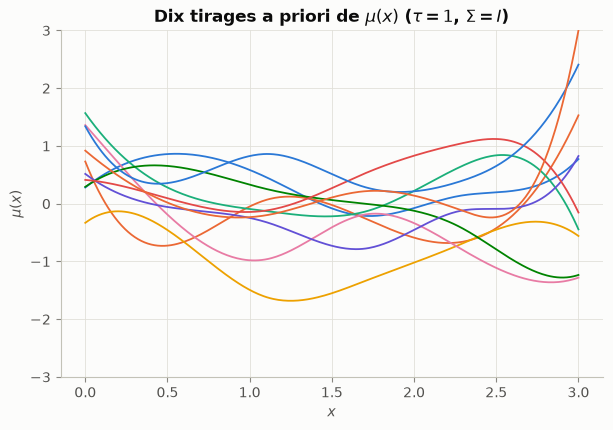

In [19]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for b in range(10):
    ax.plot(x_grid, H_grid @ rng.randn(7), color=COLORS[b % len(COLORS)], lw=1.3)
ax.set(title=r"Dix tirages a priori de $\mu(x)$ ($\tau=1$, $\Sigma=I$)", xlabel="$x$",
       ylabel=r"$\mu(x)$", ylim=(-3, 3))
plt.show()

### Calcul de la loi a posteriori

À une constante près (ne dépendant pas de $\beta$), la log-densité a posteriori est la
somme de la log-vraisemblance et du log-a priori :

$$\log\Pr(\beta\mid y) = -\frac{1}{2\sigma^2}\|y - H\beta\|^2 - \frac{1}{2\tau}
\beta^T\Sigma^{-1}\beta + c.$$

On développe : $\|y - H\beta\|^2 = \beta^TH^TH\beta - 2\beta^TH^Ty + y^Ty$. En posant
$A = H^TH + \frac{\sigma^2}{\tau}\Sigma^{-1}$ (symétrique définie positive) :

$$\log\Pr(\beta\mid y) = -\frac{1}{2\sigma^2}\big[\beta^TA\beta - 2\beta^TH^Ty\big] + c'
= -\frac{1}{2\sigma^2}(\beta - A^{-1}H^Ty)^TA(\beta - A^{-1}H^Ty) + c''$$

(on a « complété le carré »). On reconnaît la log-densité d'une loi normale :

$$E(\beta\mid Z) = \Big(H^TH + \frac{\sigma^2}{\tau}\Sigma^{-1}\Big)^{-1}H^Ty, \qquad
\mathrm{cov}(\beta\mid Z) = \Big(H^TH + \frac{\sigma^2}{\tau}\Sigma^{-1}\Big)^{-1}\sigma^2.
\qquad \text{(éq. (8.27))}$$

Pour $\mu(x) = h(x)^T\beta$ on en déduit $E(\mu(x)\mid Z) = h(x)^TE(\beta\mid Z)$ et
$\mathrm{cov}[\mu(x), \mu(x')\mid Z] = h(x)^T\mathrm{cov}(\beta\mid Z)h(x')$ (éq. (8.28)).

> **Remarque.** La moyenne a posteriori est un estimateur **ridge** (chapitre 3) de
> paramètre $\sigma^2/\tau$ : l'a priori « tire » les coefficients vers 0.

**Figure 8.4.** Dix tirages a posteriori pour $\tau = 1$ et $\tau = 1000$ ($\sigma^2$ est
remplacé par $\hat\sigma^2$). La courbe épaisse est la moyenne a posteriori.

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, tau in zip(ax, [1, 1000]):
    m, C = inf.gaussian_posterior(H, y, sigma2_hat, tau)
    draws = rng.multivariate_normal(m, C, size=10)
    a.scatter(x, y, color=GRAY, s=14, alpha=0.8)
    for d in draws:
        a.plot(x_grid, H_grid @ d, color=BLUE, lw=1, alpha=0.7)
    a.plot(x_grid, H_grid @ m, color=COLORS[6], lw=2.5, label="moyenne a posteriori")
    a.set(title=r"Tirages a posteriori, $\tau = %g$" % tau, xlabel="$x$")
    a.legend(loc="upper left")
ax[0].set_ylabel(r"$\mu(x)$")
plt.show()